# Task 11, Notebook 04: Evaluation, misranking analysis, outputs and conclusion

**Programme:** Aura Workforce by Growmar, AI/ML track, CortexHR **Phase 3: Intelligence**  
**Task:** 11: Rank resumes against job descriptions  
**Objective:** Report ranking quality against human labels, explain five misranked resumes, deliver the top-5 lists, the API contract and the saved engine.  
**Workflow stages covered in this notebook:** 29, 30, 31, 32, 33, 34, 35, 36, 37, 38 of the 38-stage Phase 1/2 standard.  
**Rule for every number below:** it is printed by the code in the same notebook; nothing is typed in by hand.

In [1]:
import sys, warnings, pathlib
warnings.filterwarnings('ignore')
ROOT = pathlib.Path.cwd().resolve()
while not (ROOT / 'config' / 'phase3_config.yaml').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src'))
import numpy as np, pandas as pd, matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 40); pd.set_option('display.max_colwidth', 80)
from cortexhr.phase3.common.config import load_config
from cortexhr.phase3.common import paths as P
CFG = load_config(); SEED = CFG['seed']
print('project root:', ROOT.name, '| seed:', SEED)

project root: phase3_working | seed: 42


In [2]:
from cortexhr.phase3.common.io import read_csv
from cortexhr.phase3.resume import text as T
from cortexhr.phase3.common.validation import profile
resumes = read_csv('resumes'); jobs = read_csv('job_descriptions'); labels = read_csv('resume_job_labels'); pairs = read_csv('resume_bias_pairs')
dd = read_csv('data_dictionary')
print('resumes', resumes.shape, '| jobs', jobs.shape, '| labels', labels.shape, '| twin pairs', pairs.shape)

resumes (185, 15) | jobs (10, 11) | labels (555, 7) | twin pairs (25, 8)


In [3]:
from cortexhr.phase3.resume.scoring import ResumeRanker
from cortexhr.phase3.resume.metrics import attach_labels, evaluate, random_baseline
v1 = ResumeRanker(mask=False).fit(resumes, jobs)      # resume_text exactly as given
v2 = ResumeRanker(mask=True).fit(resumes, jobs)       # identifiers masked before scoring (final engine)
def score_labelled(r): return attach_labels(r.score_all(labels[['resume_id', 'job_id']]), labels)

## Stage 29: Model Evaluation

*What this stage is for:* Metrics suited to the problem, against the baseline.

Ranking quality table. `relevant` = shortlisted by humans (score 4 or 5). NDCG@5 uses the graded 1 to 5 score.

In [4]:
ev2 = score_labelled(v2); per, agg = evaluate(ev2, 5); per.round(3)

  job_id  candidates  relevant  precision@5  recall@5  hit_rate@5  ndcg@5  mrr  average_precision  r_precision
0    J01          64         7          1.0     0.714         1.0   0.959  1.0              0.933        0.714
1    J02          47         3          0.4     0.667         1.0   0.894  1.0              0.810        0.667
2    J03          60        12          1.0     0.417         1.0   0.902  1.0              0.987        0.917
3    J04          62        16          1.0     0.312         1.0   0.779  1.0              0.984        0.938
4    J05          57         9          1.0     0.556         1.0   1.000  1.0              1.000        1.000
5    J06          49         6          1.0     0.833         1.0   0.898  1.0              1.000        1.000
6    J07          49         8          1.0     0.625         1.0   1.000  1.0              0.986        0.875
7    J08          55         9          1.0     0.556         1.0   1.000  1.0              0.930        0.778
8

In [5]:
rb = random_baseline(ev2, 5, 300, SEED)
table = pd.DataFrame({'final engine (v2, masked)': agg, 'random ordering': rb}).T[['precision@5', 'recall@5', 'hit_rate@5', 'ndcg@5', 'mrr', 'average_precision', 'r_precision']].round(3)
from cortexhr.phase3.common.io import save_table
save_table(per, P.task_dir(11) / 'ranking_quality_per_job.csv'); save_table(table.reset_index(names='engine'), P.task_dir(11) / 'ranking_quality_summary.csv'); table

                           precision@5  recall@5  hit_rate@5  ndcg@5    mrr  average_precision  r_precision
final engine (v2, masked)        0.940     0.549       1.000   0.923  1.000              0.960        0.882
random ordering                  0.166     0.089       0.592   0.266  0.355              0.223        0.168

**How to read it.** *Precision@5*: of the 5 candidates shown, how many humans also shortlisted. *Recall@5*: of all shortlisted candidates for the job, how many are in the top 5 (limited when a job has more than 5 relevant candidates). *Hit rate@5*: share of jobs with at least one relevant candidate in the top 5. *NDCG@5*: rewards putting the best-scored candidates first. *MRR*: how early the first relevant candidate appears.

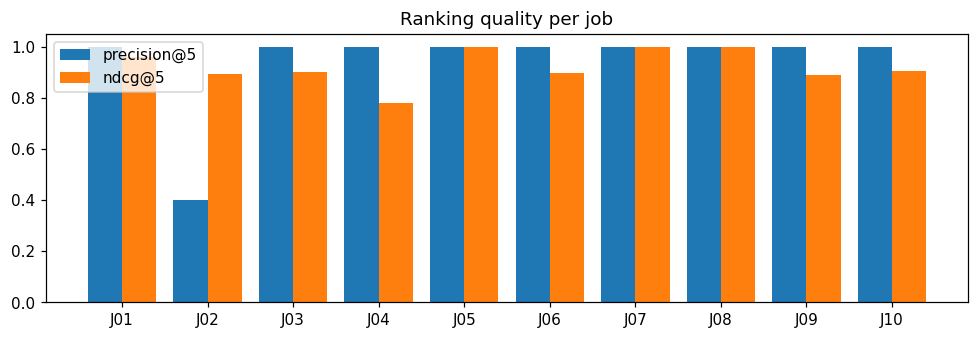

In [6]:
fig, ax = plt.subplots(figsize=(9, 3.2)); x = np.arange(len(per)); ax.bar(x - .2, per['precision@5'], .4, label='precision@5'); ax.bar(x + .2, per['ndcg@5'], .4, label='ndcg@5'); ax.set_xticks(x); ax.set_xticklabels(per.job_id); ax.set_ylim(0, 1.05); ax.legend(); ax.set_title('Ranking quality per job'); plt.tight_layout(); plt.savefig(P.FIGURES / 'task11_ranking_quality_per_job.png', dpi=130, bbox_inches='tight')

## Stage 30: Error and Misclassification Analysis

*What this stage is for:* Look at the cases the model gets wrong and say why.

Genuine misranks that have human labels. Severity is the distance from where the human score says the candidate belongs. If fewer than five exist the real number is reported.

In [7]:
from cortexhr.phase3.resume.analysis import find_misranks, diagnose
mis = find_misranks(ev2, 5, 5); print('genuine misranked pairs found:', len(find_misranks(ev2, 5, 10**6)), '| shown:', len(mis))
rows = []
for _, r in mis.iterrows():
    what, root, fix = diagnose(r)
    rows.append({'job_id': r.job_id, 'resume_id': r.resume_id, 'predicted_rank': int(r['rank']), 'human_score': int(r.rel), 'model_score': round(r.score, 3), 'misrank_type': r.misrank_type,
                 'matched_required': r.matched_required, 'missing_required': r.missing_required, 'what_went_wrong': what, 'root_cause': root, 'possible_improvement': fix})
mtab = pd.DataFrame(rows); save_table(mtab, P.task_dir(11) / 'misranking_analysis.csv'); mtab[['job_id', 'resume_id', 'predicted_rank', 'human_score', 'model_score', 'misrank_type']]

genuine misranked pairs found: 9 | shown: 5


  job_id resume_id  predicted_rank  human_score  model_score                                                              misrank_type
0    J09  RES-0012              20            5        0.335  relevant candidate ranked below clearly weaker candidates (under-ranked)
1    J03  RES-0029              34            1        0.187     weak candidate ranked above clearly stronger candidates (over-ranked)
2    J03  RES-0040              50            1        0.125     weak candidate ranked above clearly stronger candidates (over-ranked)
3    J03  RES-0054              33            1        0.188     weak candidate ranked above clearly stronger candidates (over-ranked)
4    J03  RES-0110              46            1        0.141     weak candidate ranked above clearly stronger candidates (over-ranked)

In [8]:
j2 = ev2[ev2.job_id == 'J02'].sort_values('rank').head(5)[['rank', 'resume_id', 'score', 'human_suitability_score', 'shortlist', 'required_coverage', 'missing_required']]
print('J02 has only', int(ev2[ev2.job_id == 'J02'].relevant.sum()), 'relevant candidates, so precision@5 can never exceed', round(ev2[ev2.job_id == 'J02'].relevant.sum() / 5, 2), '- the low J02 number is mostly a data limit, not a ranking failure.')
j2.round(3)

J02 has only 3 relevant candidates, so precision@5 can never exceed 0.6 - the low J02 number is mostly a data limit, not a ranking failure.


    rank resume_id  score  human_suitability_score shortlist  required_coverage                              missing_required
64     1  RES-0102  0.780                        4         Y                0.8                                 system design
65     2  RES-0042  0.670                        4         Y                0.6                         system design; docker
66     3  RES-0129  0.595                        3         N                0.6                      system design; rest apis
67     4  RES-0119  0.536                        3         N                0.6                     system design; postgresql
68     5  RES-0168  0.409                        3         N                0.2  python; system design; rest apis; postgresql

In [9]:
for _, r in mtab.iterrows(): print(f"[{r.job_id} / {r.resume_id}] rank {r.predicted_rank}, human {r.human_score}/5, score {r.model_score}\n  matched: {r.matched_required or '-'} | missing: {r.missing_required or '-'}\n  why: {r.what_went_wrong}\n  root cause: {r.root_cause}\n  improvement: {r.possible_improvement}\n")

[J09 / RES-0012] rank 20, human 5/5, score 0.335
  matched: b2b sales; negotiation | missing: crm; lead generation; presentation skills
  why: Human scored it 5/5 although 3 required skill(s) are not found in the text (crm, lead generation, presentation skills).
  root cause: Human reviewers valued overall profile more than strict skill coverage; required_coverage pushed the score down.
  improvement: Add related-skill credit (e.g. a skill graph) or a softer coverage for near-miss skills; review the label with the recruiter.

[J03 / RES-0029] rank 34, human 1/5, score 0.187
  matched: excel | missing: sql; python; data visualization; statistics
  why: Humans rated it 1/5, yet it outranks candidates they rated at least 2 points higher. Required skill coverage is 20%, text similarity 0.02, experience fit 0.50.
  root cause: All candidates around this rank miss most required skills, so the order between them is decided by weak signals (text similarity and experience); the score difference

## Stage 31: Explainability and Feature Importance

*What this stage is for:* What drives the output, in plain words.

How to explain the score to a recruiter, with one real example.

In [10]:
top = v2.top_k('J01', 5)
print('SCORE =', ' + '.join(f"{w} x {k}" for k, w in v2.weights.items()), '(each part 0 to 1)')
top[['rank', 'resume_id', 'score', 'tfidf_scaled', 'required_coverage', 'nice_coverage', 'experience_score', 'matched_required', 'missing_required', 'recommendation']].round(3)

SCORE = 0.3 x tfidf + 0.4 x required_skill + 0.1 x nice_skill + 0.2 x experience (each part 0 to 1)


   rank resume_id  score  tfidf_scaled  required_coverage  nice_coverage  experience_score                              matched_required missing_required                                                     recommendation
0     1  RES-0138  0.825         0.805                1.0          0.833               0.5  python; sql; rest apis; git; data structures                    Strong match: put on the recruiter's shortlist for human review.
1     2  RES-0151  0.803         1.000                0.8          0.833               0.5          sql; rest apis; git; data structures           python   Strong match: put on the recruiter's shortlist for human review.
2     3  RES-0161  0.794         0.758                1.0          0.667               0.5  python; sql; rest apis; git; data structures                    Strong match: put on the recruiter's shortlist for human review.
3     4  RES-0123  0.794         0.758                1.0          0.667               0.5  python; sql; rest apis; 

## Stage 32: Fairness and Bias Evaluation

*What this stage is for:* Gaps between groups, measured with the protected attributes only after the fact.

Detailed fairness work is Task 12. Here is the headline check: the effect of masking on the 25 twin pairs.

In [11]:
from cortexhr.phase3.fairness.twins import twin_gaps, gap_summary
g1, g2 = twin_gaps(v1, pairs, labels), twin_gaps(v2, pairs, labels)
pd.DataFrame({'v1 (text as given)': gap_summary(g1), 'v2 (masked)': gap_summary(g2)}).round(6)

                                v1 (text as given)  v2 (masked)
comparisons                              75.000000    75.000000
pairs                                    25.000000    25.000000
mean_abs_gap                              0.000126     0.000000
median_abs_gap                            0.000028     0.000000
max_abs_gap                               0.001619     0.000000
mean_signed_gap(twin-original)           -0.000031     0.000000
comparisons_with_nonzero_gap             74.000000     0.000000
comparisons_above_tolerance               2.000000     0.000000
mean_abs_relative_gap_pct                 0.069062     0.000000
share_twin_ranked_higher                  0.480000     0.426667
mean_abs_rank_difference                  1.000000     1.000000

## Stage 33: Model Calibration or Prediction Reliability

*What this stage is for:* Are the numbers trustworthy as numbers?

A ranking score is **not a probability**. It orders candidates; it does not say 'X% chance of being hired'. Reliability here means: are the quality numbers stable? Bootstrap over jobs.

In [12]:
rng = np.random.default_rng(SEED); boots = [per.sample(len(per), replace=True, random_state=int(rng.integers(1e9)))[['precision@5', 'ndcg@5', 'hit_rate@5']].mean() for _ in range(2000)]
ci = pd.DataFrame(boots).quantile([.025, .5, .975]).T.round(3); ci.columns = ['2.5%', 'median', '97.5%']; ci

              2.5%  median  97.5%
precision@5  0.820   0.940   1.00
ndcg@5       0.879   0.923   0.96
hit_rate@5   1.000   1.000   1.00

## Stage 34: Model Comparison and Final Selection

*What this stage is for:* Choose on evidence, not on the highest score alone.

v1 (text as given) versus v2 (masked). v2 is the final engine because it removes protected information from the score; ranking quality is compared so fairness does not silently cost accuracy.

In [13]:
ev1 = score_labelled(v1); _, a1 = evaluate(ev1, 5)
cmp_ = pd.DataFrame({'v1 unmasked': a1, 'v2 masked (final)': agg}).T[['precision@5', 'recall@5', 'hit_rate@5', 'ndcg@5', 'mrr']].round(4); cmp_['delta_vs_v1'] = ''
print('NDCG@5 change from masking: %+.4f | precision@5 change: %+.4f' % (agg['ndcg@5'] - a1['ndcg@5'], agg['precision@5'] - a1['precision@5'])); cmp_

NDCG@5 change from masking: -0.0030 | precision@5 change: -0.0200


                   precision@5  recall@5  hit_rate@5  ndcg@5  mrr delta_vs_v1
v1 unmasked               0.96    0.5825         1.0  0.9258  1.0            
v2 masked (final)         0.94    0.5491         1.0  0.9228  1.0            

## Stage 35: Final Prediction Generation

*What this stage is for:* Produce the deliverable.

Top 5 candidates for every job: (a) inside the labelled pool (comparable with human labels), (b) across all 185 resumes (what the API returns).

In [14]:
frames = []
for jid in jobs.job_id:
    t = v2.top_k(jid, 5); t.insert(0, 'job_id_', jid); frames.append(t)
top_all = pd.concat(frames, ignore_index=True)
cols = ['job_id', 'rank', 'resume_id', 'score', 'tfidf_scaled', 'required_coverage', 'nice_coverage', 'experience_score', 'matched_required', 'missing_required', 'total_years', 'relevant_years', 'recommendation', 'human_review']
save_table(top_all[cols], P.task_dir(11) / 'top5_per_job_all_resumes.csv'); print(top_all.shape); top_all[cols].head(10).round(3)

(50, 20)


  job_id  rank resume_id  score  tfidf_scaled  required_coverage  nice_coverage  experience_score                              matched_required          missing_required  total_years  relevant_years                                                     recommendation                                                   human_review
0    J01     1  RES-0138  0.825         0.805                1.0          0.833             0.500  python; sql; rest apis; git; data structures                                    6.4               0   Strong match: put on the recruiter's shortlist for human review.  Required: ranking is decision support, not a hiring decision.
1    J01     2  RES-0151  0.803         1.000                0.8          0.833             0.500          sql; rest apis; git; data structures                    python          3.2               0   Strong match: put on the recruiter's shortlist for human review.  Required: ranking is decision support, not a hiring decision.
2    J01     

## Stage 36: Output and Business Validation

*What this stage is for:* Check the output against the required format and read it as the user would.

Output and business validation: required fields exist, no protected field appears, and the API contract is tested on good and bad requests.

In [15]:
from cortexhr.phase3.resume.api import handle_rank_request, ApiError, FORBIDDEN_FIELDS
resp = handle_rank_request({'job_id': 'J01', 'top_k': 3}, v2)
print('response keys:', list(resp)); print('first candidate:', {k: resp['candidates'][0][k] for k in ('rank', 'resume_id', 'score', 'score_breakdown')})
leak = [f for f in FORBIDDEN_FIELDS if f in str(resp).lower().replace('never_used', '')]
print('protected fields present in the response:', leak or 'none')
for bad in ({'job_id': 'J01', 'gender': 'F'}, {'job_id': 'J01', 'top_k': 99}, {'job_id': 'NOPE'}, {}):
    try: handle_rank_request(bad, v2)
    except ApiError as e: print(e.status, e.body())

response keys: ['engine_version', 'job_id', 'top_k', 'candidates', 'used_inputs', 'never_used', 'weights', 'notice']
first candidate: {'rank': 1, 'resume_id': 'RES-0138', 'score': 0.8247, 'score_breakdown': {'text_similarity': 0.8047, 'required_skill_coverage': 1.0, 'nice_to_have_coverage': 0.8333, 'experience_fit': 0.5}}
protected fields present in the response: ['candidate_name', 'name', 'gender', 'age', 'college_tier', 'email', 'city']
422 {'error': 'validation', 'details': ["fields not accepted (never used in ranking): ['gender']"]}
422 {'error': 'validation', 'details': ['top_k must be an integer from 1 to 20']}
404 {'error': 'unknown job_id', 'details': ['NOPE']}
422 {'error': 'validation', 'details': ['provide exactly one of job_id or job']}


## Stage 37: Model Saving, Versioning and Reproducibility

*What this stage is for:* Artifacts, metadata, seeds, environment.

Save the fitted engine with version, weights, inputs and environment. Existing Phase 1 and Phase 2 artifacts are not touched.

In [16]:
import joblib, hashlib, platform, sklearn
from cortexhr.phase3.common.io import save_json, utc_now
joblib.dump(v2, P.MODELS / 'resume_ranker_v2.joblib')
meta = {'engine_version': v2.used_inputs()['version'], 'created_utc': utc_now(), 'weights': v2.weights, 'score_inputs': v2.used_inputs()['score_inputs'], 'never_used': v2.used_inputs()['never_used'],
        'metrics_labelled_pool': {k: round(v, 4) for k, v in agg.items()}, 'random_baseline': {k: round(v, 4) for k, v in rb.items()}, 'seed': SEED, 'sklearn': sklearn.__version__, 'python': platform.python_version(),
        'sha256': hashlib.sha256(open(P.MODELS / 'resume_ranker_v2.joblib', 'rb').read()).hexdigest()}
save_json(meta, P.METADATA / 'resume_ranker_v2_metadata.json'); meta['engine_version'], meta['sha256'][:12]

('resume-ranker-v2-masked', '0e4c1a5600e4')

## Stage 38: Final Findings, Limitations and Conclusion

*What this stage is for:* What was found, what remains, what must not be done with it.

In [17]:
print('FINDINGS'); print('- Final engine (v2 masked): precision@5 %.2f, NDCG@5 %.2f, hit rate@5 %.2f versus random %.2f / %.2f / %.2f.' % (agg['precision@5'], agg['ndcg@5'], agg['hit_rate@5'], rb['precision@5'], rb['ndcg@5'], rb['hit_rate@5']))
weak = per.sort_values('precision@5').iloc[0]; print('- Weakest job: %s (precision@5 %.2f, %d relevant candidates).' % (weak.job_id, weak['precision@5'], weak.relevant))
print('- Masking changed NDCG@5 by %+.3f.' % (agg['ndcg@5'] - a1['ndcg@5']))
allm = find_misranks(ev2, 5, 10**6); print('- Genuine misranks found: %d (%d under-ranked relevant, %d over-ranked weak); none reaches the top-5 of any job except as noted for J02.' % (len(allm), allm.misrank_type.str.contains('under').sum(), allm.misrank_type.str.contains('over').sum()))
print('LIMITS: 10 jobs and 555 human labels are small; skills outside the vocabulary are invisible; years are capped so more experience never beats the requirement; the score ranks, it does not predict hiring; a recruiter must review every candidate.')

FINDINGS
- Final engine (v2 masked): precision@5 0.94, NDCG@5 0.92, hit rate@5 1.00 versus random 0.17 / 0.27 / 0.59.
- Weakest job: J02 (precision@5 0.40, 3 relevant candidates).
- Masking changed NDCG@5 by -0.003.
- Genuine misranks found: 9 (2 under-ranked relevant, 7 over-ranked weak); none reaches the top-5 of any job except as noted for J02.
LIMITS: 10 jobs and 555 human labels are small; skills outside the vocabulary are invisible; years are capped so more experience never beats the requirement; the score ranks, it does not predict hiring; a recruiter must review every candidate.
